In [2]:
import numpy as np
import matplotlib.pyplot as plt

print("ready")

ready


In [3]:
# --- Model parameters ---
N = 50          # number of agents
T = 100         # number of trials
T_drift = 50    # trial at which AI reliability silently drops

p_high = 0.90   # AI reliability before drift
p_low  = 0.55   # AI reliability after drift

alpha  = 0.15   # learning rate (sensitivity)
theta  = 0.25   # switch threshold (criterion)

initial_trust = 0.85  # starting trust for all agents

print(f"Drift happens at trial {T_drift} of {T}")
print(f"Reliability drops from {p_high} to {p_low}")

Drift happens at trial 50 of 100
Reliability drops from 0.9 to 0.55


In [4]:
# --- Run simulation ---
np.random.seed(42)  # makes results reproducible

# Store trust trajectory for each agent across all trials
trust_history = np.zeros((N, T))

# Store which trial each agent switches at (None if they never switch)
switch_trial = [None] * N

for i in range(N):
    trust = initial_trust
    switched = False

    for t in range(T):
        # Set AI reliability based on whether drift has happened
        p = p_high if t < T_drift else p_low

        # AI produces outcome: 1 = correct, 0 = incorrect
        outcome = np.random.binomial(1, p)

        # Delta-rule trust update
        trust = trust + alpha * (outcome - trust)

        # Record trust at this trial
        trust_history[i, t] = trust

        # Check switch condition (only switch once)
        if not switched and (initial_trust - trust) > theta:
            switch_trial[i] = t
            switched = True

print(f"Agents who switched: {sum(s is not None for s in switch_trial)} / {N}")
print(f"Agents who never switched: {sum(s is None for s in switch_trial)} / {N}")

Agents who switched: 50 / 50
Agents who never switched: 0 / 50


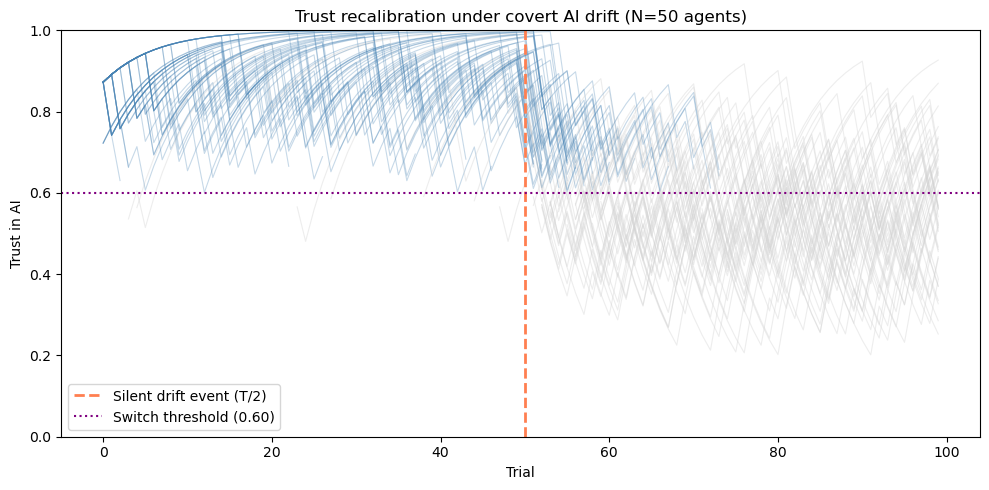

In [5]:
# --- Plot trust trajectories ---
fig, ax = plt.subplots(figsize=(10, 5))

for i in range(N):
    sw = switch_trial[i]
    # Blue before switch, grey after
    if sw is not None:
        ax.plot(range(sw), trust_history[i, :sw], 
                color='steelblue', alpha=0.3, linewidth=0.8)
        ax.plot(range(sw, T), trust_history[i, sw:], 
                color='lightgrey', alpha=0.4, linewidth=0.8)
    else:
        ax.plot(range(T), trust_history[i], 
                color='steelblue', alpha=0.3, linewidth=0.8)

# Mark the drift event
ax.axvline(x=T_drift, color='coral', linewidth=2, 
           linestyle='--', label='Silent drift event (T/2)')

# Mark the switch threshold
ax.axhline(y=initial_trust - theta, color='purple', linewidth=1.5,
           linestyle=':', label=f'Switch threshold ({initial_trust - theta:.2f})')

ax.set_xlabel('Trial')
ax.set_ylabel('Trust in AI')
ax.set_title('Trust recalibration under covert AI drift (N=50 agents)')
ax.legend()
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [6]:
# --- Summary stats ---
switch_trials_only = [s for s in switch_trial if s is not None]

print(f"Mean trial of switch: {np.mean(switch_trials_only):.1f}")
print(f"Earliest switch: trial {min(switch_trials_only)}")
print(f"Latest switch: trial {max(switch_trials_only)}")
print(f"Trials are post-drift from trial 50 onwards")
print(f"Mean trials AFTER drift to switch: {np.mean([s - T_drift for s in switch_trials_only]):.1f}")

Mean trial of switch: 54.2
Earliest switch: trial 3
Latest switch: trial 74
Trials are post-drift from trial 50 onwards
Mean trials AFTER drift to switch: 4.2


In [7]:
# --- V2 Parameters: condition manipulation ---

# Neutral condition (baseline)
alpha_neutral = 0.15
theta_neutral = 0.25

# Anthropomorphic condition: same sensitivity, higher criterion
alpha_anthro  = 0.15
theta_anthro  = 0.40   # needs more evidence before switching

# Half agents in each condition
N_each = 25

print(f"Neutral:        alpha={alpha_neutral}, theta={theta_neutral}")
print(f"Anthropomorphic: alpha={alpha_anthro},  theta={theta_anthro}")
print(f"Agents per condition: {N_each}")

Neutral:        alpha=0.15, theta=0.25
Anthropomorphic: alpha=0.15,  theta=0.4
Agents per condition: 25


### What v1 demonstrates

The baseline simulation shows that a simple delta-rule trust update with a fixed switching threshold produces the expected pattern: trust rises during the pre-drift phase as agents accumulate evidence of reliable performance, then falls after the drift event as errors accumulate. All 50 agents eventually cross the threshold, with a mean switch trial of 54.2 — approximately 4 trials after the drift event. The variance in switch times reflects stochasticity in AI outcomes: even a 55%-reliable AI produces correct responses on some trials, creating the individual trajectory variation visible in the plot. This establishes that the mechanism produces recalibration, confirming the basic architecture works before the theoretical manipulation is introduced in v2.

### Why anthropomorphism is operationalised as a threshold (criterion) shift, not a learning rate (sensitivity) shift

This is a deliberate theoretical choice, not a modelling convenience. The architecture maps onto Signal Detection Theory: alpha corresponds to sensitivity (how fast errors are registered), theta corresponds to criterion (how much accumulated evidence is required before behaviour changes). The empirical anchor for the anthropomorphic-as-criterion-shift claim is Peters and Scharlau (2025), who showed that explicit scepticism instructions did not improve participants' *detection* of AI degradation (self-reported trust still dropped during the error phase), but did not translate into behavioural change either. Detection and action dissociated.

If anthropomorphism impaired learning (alpha shift), agents would fail to register errors at all. The literature does not support this: Waytz et al. (2014) shows social cues raise initial trust, but not that they prevent error detection. What social framing appears to raise is the threshold for acting on detected degradation — social forgiveness, relational inertia, reluctance to "betray" a social entity. This maps onto theta, not alpha. Keeping alpha constant across conditions is therefore the more conservative and more empirically grounded claim.

In [8]:
# --- V2 Simulation: two conditions ---
np.random.seed(42)

def run_simulation(n_agents, alpha, theta):
    """Run simulation for one condition, return results dict."""
    trust_history = np.zeros((n_agents, T))
    switch_trial  = [None] * n_agents
    cumulative_cost = np.zeros(n_agents)  # trials spent following degraded AI

    for i in range(n_agents):
        trust   = initial_trust
        switched = False

        for t in range(T):
            p       = p_high if t < T_drift else p_low
            outcome = np.random.binomial(1, p)

            trust   = trust + alpha * (outcome - trust)
            trust_history[i, t] = trust

            # Cumulative cost: count post-drift trials before switching
            if t >= T_drift and not switched:
                cumulative_cost[i] += 1

            if not switched and (initial_trust - trust) > theta:
                switch_trial[i] = t
                switched = True

    return {
        'trust_history':   trust_history,
        'switch_trial':    switch_trial,
        'cumulative_cost': cumulative_cost
    }

results_neutral = run_simulation(N_each, alpha_neutral, theta_neutral)
results_anthro  = run_simulation(N_each, alpha_anthro,  theta_anthro)

print("Neutral condition:")
switched_n = [s for s in results_neutral['switch_trial'] if s is not None]
print(f"  Switched: {len(switched_n)}/{N_each}")
print(f"  Mean trial of switch: {np.mean(switched_n):.1f}")
print(f"  Mean cumulative cost: {np.mean(results_neutral['cumulative_cost']):.1f} trials")

print("\nAnthropomorphic condition:")
switched_a = [s for s in results_anthro['switch_trial'] if s is not None]
print(f"  Switched: {len(switched_a)}/{N_each}")
print(f"  Mean trial of switch: {np.mean(switched_a):.1f}")
print(f"  Mean cumulative cost: {np.mean(results_anthro['cumulative_cost']):.1f} trials")

Neutral condition:
  Switched: 25/25
  Mean trial of switch: 53.3
  Mean cumulative cost: 8.1 trials

Anthropomorphic condition:
  Switched: 24/25
  Mean trial of switch: 69.3
  Mean cumulative cost: 21.5 trials


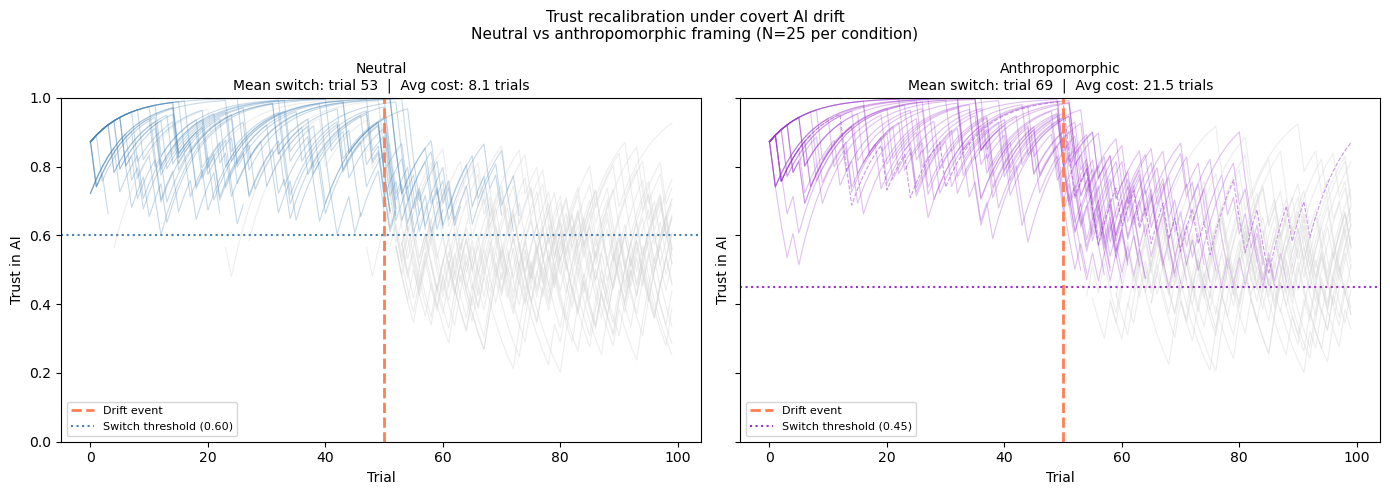

In [9]:
# --- V2 Plot: side-by-side trust trajectories ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

conditions = [
    (results_neutral, 'Neutral',          'steelblue',  theta_neutral),
    (results_anthro,  'Anthropomorphic',  'darkorchid', theta_anthro),
]

for ax, (results, label, colour, theta) in zip(axes, conditions):
    th = results['trust_history']
    sw = results['switch_trial']
    n  = th.shape[0]

    for i in range(n):
        s = sw[i]
        if s is not None:
            ax.plot(range(s), th[i, :s],
                    color=colour, alpha=0.3, linewidth=0.8)
            ax.plot(range(s, T), th[i, s:],
                    color='lightgrey', alpha=0.4, linewidth=0.8)
        else:
            ax.plot(range(T), th[i],
                    color=colour, alpha=0.5, linewidth=0.8,
                    linestyle='--')   # dashed = never switched

    ax.axvline(x=T_drift, color='coral', linewidth=2,
               linestyle='--', label='Drift event')
    ax.axhline(y=initial_trust - theta, color=colour,
               linewidth=1.5, linestyle=':',
               label=f'Switch threshold ({initial_trust - theta:.2f})')

    switched = [s for s in sw if s is not None]
    ax.set_title(
        f'{label}\n'
        f'Mean switch: trial {np.mean(switched):.0f}  |  '
        f'Avg cost: {np.mean(results["cumulative_cost"]):.1f} trials',
        fontsize=10
    )
    ax.set_xlabel('Trial')
    ax.set_ylabel('Trust in AI')
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)

plt.suptitle(
    'Trust recalibration under covert AI drift\n'
    'Neutral vs anthropomorphic framing (N=25 per condition)',
    fontsize=11
)
plt.tight_layout()
plt.show()

In [10]:
# --- Save figure ---
fig.savefig('trust_recalibration_v2.png', dpi=150, bbox_inches='tight')
print("Figure saved.")

Figure saved.


In [10]:
# --- Save figure ---
fig.savefig('trust_recalibration_v2.png', dpi=150, bbox_inches='tight')
print("Figure saved.")

Figure saved.


### What v2 demonstrates

Introducing the anthropomorphic condition produces a substantial and theoretically predicted difference. Neutral agents switch at a mean of trial 53.3 with a mean cumulative cost of 8.1 trials following the degraded AI. Anthropomorphic agents switch at a mean of trial 69.3 with a cumulative cost of 21.5 trials — a 16-trial delay and a 2.7x cost increase. One anthropomorphic agent fails to switch within the 100-trial window. The condition difference is entirely driven by the theta shift from 0.25 to 0.40: anthropomorphic agents require substantially more accumulated trust loss before their behaviour changes, even though their detection sensitivity (alpha) is identical to neutral agents. This is the model's central prediction, and v2 confirms it holds under homogeneous-agent conditions.

In [11]:
# --- V3: heterogeneous agent parameters ---
np.random.seed(42)

# Number of simulations to run
N_SIMS = 10
N_each = 25

# Parameter distributions
ALPHA_MEAN = 0.15; ALPHA_SD = 0.03

THETA_MEAN_NEUTRAL = 0.25; THETA_SD = 0.05
THETA_MEAN_ANTHRO  = 0.40; THETA_SD = 0.05

def run_simulation_v3(n_agents, alpha_mean, alpha_sd, theta_mean, theta_sd):
    """Run one simulation with heterogeneous agents drawn from distributions."""
    
    # Draw individual parameters for each agent
    alphas = np.random.normal(alpha_mean, alpha_sd, n_agents).clip(0.01, 0.99)
    thetas = np.random.normal(theta_mean, theta_sd, n_agents).clip(0.05, 0.99)
    
    trust_history   = np.zeros((n_agents, T))
    switch_trial    = [None] * n_agents
    cumulative_cost = np.zeros(n_agents)

    for i in range(n_agents):
        trust    = initial_trust
        switched = False

        for t in range(T):
            p       = p_high if t < T_drift else p_low
            outcome = np.random.binomial(1, p)

            trust   = trust + alphas[i] * (outcome - trust)
            trust_history[i, t] = trust

            if t >= T_drift and not switched:
                cumulative_cost[i] += 1

            if not switched and (initial_trust - trust) > thetas[i]:
                switch_trial[i] = t
                switched = True

    return {
        'trust_history':   trust_history,
        'switch_trial':    switch_trial,
        'cumulative_cost': cumulative_cost,
        'alphas':          alphas,
        'thetas':          thetas
    }

# Run N_SIMS simulations for each condition, collect results
all_switch_neutral = []
all_switch_anthro  = []
all_cost_neutral   = []
all_cost_anthro    = []
all_never_neutral  = []
all_never_anthro   = []

for sim in range(N_SIMS):
    r_n = run_simulation_v3(N_each, ALPHA_MEAN, ALPHA_SD,
                            THETA_MEAN_NEUTRAL, THETA_SD)
    r_a = run_simulation_v3(N_each, ALPHA_MEAN, ALPHA_SD,
                            THETA_MEAN_ANTHRO,  THETA_SD)

    all_switch_neutral.extend([s for s in r_n['switch_trial'] if s is not None])
    all_switch_anthro.extend( [s for s in r_a['switch_trial'] if s is not None])
    all_cost_neutral.extend(r_n['cumulative_cost'].tolist())
    all_cost_anthro.extend( r_a['cumulative_cost'].tolist())
    all_never_neutral.append(sum(s is None for s in r_n['switch_trial']))
    all_never_anthro.append( sum(s is None for s in r_a['switch_trial']))

print("Across 10 simulations (250 agents per condition):")
print(f"\nNeutral condition:")
print(f"  Mean switch trial:     {np.mean(all_switch_neutral):.1f}")
print(f"  Mean cumulative cost:  {np.mean(all_cost_neutral):.1f} trials")
print(f"  Never switched:        {sum(all_never_neutral)} / {N_SIMS * N_each} agents")

print(f"\nAnthropomorphic condition:")
print(f"  Mean switch trial:     {np.mean(all_switch_anthro):.1f}")
print(f"  Mean cumulative cost:  {np.mean(all_cost_anthro):.1f} trials")
print(f"  Never switched:        {sum(all_never_anthro)} / {N_SIMS * N_each} agents")

Across 10 simulations (250 agents per condition):

Neutral condition:
  Mean switch trial:     55.5
  Mean cumulative cost:  10.0 trials
  Never switched:        1 / 250 agents

Anthropomorphic condition:
  Mean switch trial:     66.7
  Mean cumulative cost:  20.5 trials
  Never switched:        21 / 250 agents


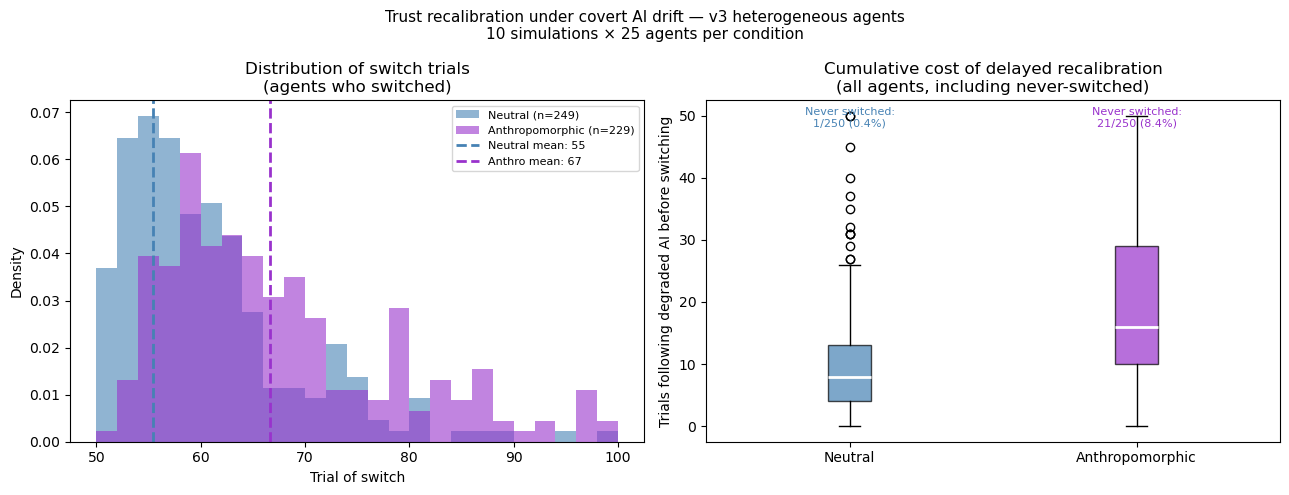

Figure saved.


In [16]:
# --- V3 Plot: distributions of switch trials and cumulative cost ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Plot 1: histogram of switch trials ---
ax = axes[0]
bins = range(T_drift, T + 2, 2)

ax.hist(all_switch_neutral, bins=bins, alpha=0.6,
        color='steelblue', label=f'Neutral (n={len(all_switch_neutral)})',
        density=True)
ax.hist(all_switch_anthro, bins=bins, alpha=0.6,
        color='darkorchid', label=f'Anthropomorphic (n={len(all_switch_anthro)})',
        density=True)

ax.axvline(np.mean(all_switch_neutral), color='steelblue',
           linewidth=2, linestyle='--',
           label=f'Neutral mean: {np.mean(all_switch_neutral):.0f}')
ax.axvline(np.mean(all_switch_anthro), color='darkorchid',
           linewidth=2, linestyle='--',
           label=f'Anthro mean: {np.mean(all_switch_anthro):.0f}')

ax.set_xlabel('Trial of switch')
ax.set_ylabel('Density')
ax.set_title('Distribution of switch trials\n(agents who switched)')
ax.legend(fontsize=8)

# --- Plot 2: cumulative cost boxplot ---
ax = axes[1]
bp = ax.boxplot(
    [all_cost_neutral, all_cost_anthro],
    tick_labels=['Neutral', 'Anthropomorphic'],
    patch_artist=True,
    medianprops=dict(color='white', linewidth=2)
)
bp['boxes'][0].set_facecolor('steelblue')
bp['boxes'][1].set_facecolor('darkorchid')
for box in bp['boxes']:
    box.set_alpha(0.7)

ax.set_ylabel('Trials following degraded AI before switching')
ax.set_title('Cumulative cost of delayed recalibration\n(all agents, including never-switched)')

# Annotate never-switched counts
never_n = sum(all_never_neutral)
never_a = sum(all_never_anthro)
ax.text(1, ax.get_ylim()[1] * 0.92,
        f'Never switched:\n{never_n}/250 ({never_n/250*100:.1f}%)',
        ha='center', fontsize=8, color='steelblue')
ax.text(2, ax.get_ylim()[1] * 0.92,
        f'Never switched:\n{never_a}/250 ({never_a/250*100:.1f}%)',
        ha='center', fontsize=8, color='darkorchid')

plt.suptitle(
    'Trust recalibration under covert AI drift — v3 heterogeneous agents\n'
    '10 simulations × 25 agents per condition',
    fontsize=11
)
plt.tight_layout()
plt.show()

# Save
fig.savefig('trust_recalibration_v3.png', dpi=150, bbox_inches='tight')
print("Figure saved.")

### What v3 demonstrates

Introducing heterogeneity (alpha and theta drawn from distributions rather than fixed) and pooling results across 10 simulations tests whether the v2 condition difference is robust or an artefact of specific parameter values. It is robust: the mean switch trial difference (55.5 vs 66.7) persists, and cumulative cost doubles in the anthropomorphic condition (10.0 vs 20.5 trials). The most theoretically interesting finding is emergent: 8.4% of anthropomorphic agents (21 of 250) never switch within the simulation window, compared to 0.4% of neutral agents (1 of 250). This never-switched rate was not programmed in — it arose from the interaction of heterogeneous thetas with a stochastic AI output stream. Distributional results like this cannot be read off parameter values analytically, which is why the ABM framework is justified for this question. The finding demonstrates that anthropomorphic framing does not just delay recalibration uniformly; it produces a qualitatively different pattern in which a meaningful subpopulation remains permanently miscalibrated.

In [13]:
# --- V4: sensitivity analysis across drift trajectory ---
# Test whether the condition difference holds under gradual drift,
# not just abrupt drift. This addresses the formative feedback directly.

def get_reliability(t, T_drift, p_high, p_low, drift_type='abrupt', drift_window=20):
    """Return AI reliability at trial t, depending on drift trajectory."""
    if drift_type == 'abrupt':
        return p_high if t < T_drift else p_low
    
    elif drift_type == 'gradual':
        # Reliability declines linearly from p_high to p_low across drift_window trials
        # starting at T_drift
        if t < T_drift:
            return p_high
        elif t >= T_drift + drift_window:
            return p_low
        else:
            # Linear interpolation during the drift window
            progress = (t - T_drift) / drift_window
            return p_high - progress * (p_high - p_low)
    
    else:
        raise ValueError(f"Unknown drift_type: {drift_type}")

# Quick test: print reliability at key trials for both types
print("Trial | Abrupt | Gradual (window=20)")
for t in [40, 49, 50, 55, 60, 65, 70, 80]:
    r_abrupt  = get_reliability(t, T_drift, p_high, p_low, 'abrupt')
    r_gradual = get_reliability(t, T_drift, p_high, p_low, 'gradual', drift_window=20)
    print(f"  {t:3d}  |  {r_abrupt:.2f}  |  {r_gradual:.2f}")

Trial | Abrupt | Gradual (window=20)
   40  |  0.90  |  0.90
   49  |  0.90  |  0.90
   50  |  0.55  |  0.90
   55  |  0.55  |  0.81
   60  |  0.55  |  0.73
   65  |  0.55  |  0.64
   70  |  0.55  |  0.55
   80  |  0.55  |  0.55


In [14]:
# --- V4 Simulation: run all four conditions ---
# Two drift types (abrupt, gradual) x two framings (neutral, anthro)
np.random.seed(42)

def run_simulation_v4(n_agents, alpha_mean, alpha_sd, theta_mean, theta_sd,
                     drift_type='abrupt', drift_window=20):
    """Run simulation with specified drift trajectory."""
    alphas = np.random.normal(alpha_mean, alpha_sd, n_agents).clip(0.01, 0.99)
    thetas = np.random.normal(theta_mean, theta_sd, n_agents).clip(0.05, 0.99)
    
    trust_history   = np.zeros((n_agents, T))
    switch_trial    = [None] * n_agents
    cumulative_cost = np.zeros(n_agents)

    for i in range(n_agents):
        trust    = initial_trust
        switched = False

        for t in range(T):
            p = get_reliability(t, T_drift, p_high, p_low,
                                drift_type=drift_type, drift_window=drift_window)
            outcome = np.random.binomial(1, p)
            trust   = trust + alphas[i] * (outcome - trust)
            trust_history[i, t] = trust

            if t >= T_drift and not switched:
                cumulative_cost[i] += 1

            if not switched and (initial_trust - trust) > thetas[i]:
                switch_trial[i] = t
                switched = True

    return {
        'switch_trial':    switch_trial,
        'cumulative_cost': cumulative_cost,
        'never_switched':  sum(s is None for s in switch_trial)
    }

# Run all four conditions, 10 simulations each
results_v4 = {
    'abrupt_neutral':  {'switches': [], 'costs': [], 'never': 0},
    'abrupt_anthro':   {'switches': [], 'costs': [], 'never': 0},
    'gradual_neutral': {'switches': [], 'costs': [], 'never': 0},
    'gradual_anthro':  {'switches': [], 'costs': [], 'never': 0},
}

for sim in range(N_SIMS):
    for drift_type in ['abrupt', 'gradual']:
        for framing, theta_mean in [('neutral', THETA_MEAN_NEUTRAL),
                                    ('anthro',  THETA_MEAN_ANTHRO)]:
            key = f'{drift_type}_{framing}'
            r = run_simulation_v4(N_each, ALPHA_MEAN, ALPHA_SD,
                                  theta_mean, THETA_SD,
                                  drift_type=drift_type)
            results_v4[key]['switches'].extend(
                [s for s in r['switch_trial'] if s is not None])
            results_v4[key]['costs'].extend(r['cumulative_cost'].tolist())
            results_v4[key]['never'] += r['never_switched']

# Print comparison table
print(f"{'Condition':<22} {'Mean switch':>12} {'Mean cost':>12} {'Never switched':>16}")
print("-" * 64)
for key, r in results_v4.items():
    mean_switch = np.mean(r['switches']) if r['switches'] else float('nan')
    mean_cost = np.mean(r['costs'])
    never_pct = r['never'] / (N_SIMS * N_each) * 100
    print(f"{key:<22} {mean_switch:>12.1f} {mean_cost:>12.1f} "
          f"{r['never']:>4d}/{N_SIMS*N_each} ({never_pct:>4.1f}%)")

Condition               Mean switch    Mean cost   Never switched
----------------------------------------------------------------
abrupt_neutral                 54.9          9.3    0/250 ( 0.0%)
abrupt_anthro                  67.6         21.3   19/250 ( 7.6%)
gradual_neutral                64.5         19.2    6/250 ( 2.4%)
gradual_anthro                 78.2         33.2   48/250 (19.2%)


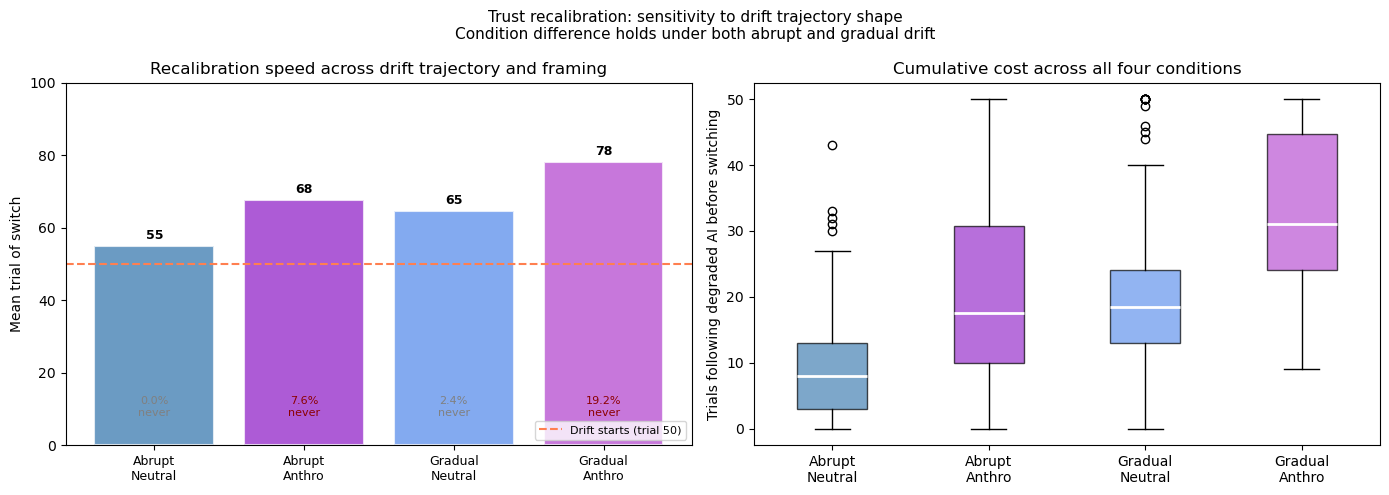

Figure saved.


In [15]:
# --- V4 Plot: 2x2 comparison of drift trajectory and framing ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: bar chart of mean switch trials and never-switched %
ax = axes[0]
conditions = ['abrupt_neutral', 'abrupt_anthro', 'gradual_neutral', 'gradual_anthro']
labels = ['Abrupt\nNeutral', 'Abrupt\nAnthro', 'Gradual\nNeutral', 'Gradual\nAnthro']
colors = ['steelblue', 'darkorchid', 'cornflowerblue', 'mediumorchid']

mean_switches = [np.mean(results_v4[k]['switches']) for k in conditions]
never_pcts    = [results_v4[k]['never'] / (N_SIMS * N_each) * 100 for k in conditions]

x = np.arange(len(conditions))
ax.bar(x, mean_switches, color=colors, alpha=0.8, edgecolor='white', linewidth=1.5)
ax.axhline(y=T_drift, color='coral', linestyle='--', linewidth=1.5,
           label=f'Drift starts (trial {T_drift})')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('Mean trial of switch')
ax.set_title('Recalibration speed across drift trajectory and framing')
ax.legend(fontsize=8, loc='lower right')
ax.set_ylim(0, 100)

# Annotate bars with never-switched percentages
for i, (switch, pct) in enumerate(zip(mean_switches, never_pcts)):
    ax.text(i, switch + 2, f'{switch:.0f}', ha='center', fontsize=9, fontweight='bold')
    ax.text(i, 8, f'{pct:.1f}%\nnever', ha='center', fontsize=8,
            color='darkred' if pct > 5 else 'gray')

# Right: cumulative cost boxplot, all four conditions
ax = axes[1]
cost_data = [results_v4[k]['costs'] for k in conditions]
bp = ax.boxplot(cost_data, tick_labels=labels, patch_artist=True,
                medianprops=dict(color='white', linewidth=2))
for box, color in zip(bp['boxes'], colors):
    box.set_facecolor(color)
    box.set_alpha(0.7)

ax.set_ylabel('Trials following degraded AI before switching')
ax.set_title('Cumulative cost across all four conditions')

plt.suptitle(
    'Trust recalibration: sensitivity to drift trajectory shape\n'
    'Condition difference holds under both abrupt and gradual drift',
    fontsize=11
)
plt.tight_layout()
plt.show()

# Save
fig.savefig('trust_recalibration_v4.png', dpi=150, bbox_inches='tight')
print("Figure saved.")

### What v4 demonstrates

The sensitivity analysis tests whether the condition difference holds under a more ecologically valid drift trajectory. Abrupt drift (reliability drops from 0.90 to 0.55 instantaneously at trial 50) is a deliberate parsimony choice that creates a clean before/after comparison. Real AI systems typically degrade gradually, so v4 implements a gradual drift across a 20-trial window. The result: the condition difference holds robustly across both drift types. Neutral agents switch at trial 54.9 under abrupt drift and trial 64.5 under gradual drift; anthropomorphic agents switch at 67.6 under abrupt and 78.2 under gradual. Never-switched rates climb from 7.6% to 19.2% in the anthropomorphic condition when drift becomes gradual. This is an important finding: gradual drift, which more closely mirrors real-world AI degradation, *amplifies* the recalibration problem rather than diminishing it. Each individual trial provides less diagnostic evidence under gradual drift, requiring more accumulated error to cross the threshold. The model's central claim is therefore robust to trajectory shape, and the more ecologically valid scenario is the more problematic one. This directly addresses the formative feedback's request for sensitivity analysis across drift trajectories.